In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import coo_matrix, diags, save_npz

import sys

_start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_start, *_start.parents] if (p / "checkpoints").exists() and (p / "processed").exists()), _start)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.dataset import get_hospital_splits

FUSION_DIR = PROJECT_ROOT / "checkpoints" / "fusion"
SCALER_PATH = FUSION_DIR / "concat_baseline" / "input_scaler.npz"
GRAPH_DIR = FUSION_DIR / "patient_graphs_knn_concat"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

K = 5

# Use the concatenation model's training-fitted scaler.
with np.load(SCALER_PATH) as scaler:
    feature_mean = scaler["mean"]
    feature_std = scaler["std"]

feature_std = feature_std.copy()
feature_std[feature_std < 1e-8] = 1.0

assert feature_mean.shape == (128,)
assert feature_std.shape == (128,)

train_dirs, val_dirs, test_dirs = get_hospital_splits(
    str(PROJECT_ROOT / "processed")
)

split_dirs = {
    "train": train_dirs,
    "val": val_dirs,
    "test": test_dirs
}


def map_patient_hospitals(patient_ids, hospital_dirs):
    patient_to_hospital = {}

    for hdir in hospital_dirs:
        path = hdir / "tabular" / "tabular_features.parquet"
        ids = pd.read_parquet(
            path, columns=["patientunitstayid"]
        )["patientunitstayid"].dropna().astype(np.int64).unique()

        for pid in ids:
            pid = int(pid)
            if pid in patient_to_hospital:
                if patient_to_hospital[pid] != hdir.name:
                    raise ValueError(
                        f"Patient {pid} appears in multiple hospitals."
                    )
            patient_to_hospital[pid] = hdir.name

    missing = [
        int(pid) for pid in patient_ids
        if int(pid) not in patient_to_hospital
    ]
    if missing:
        raise ValueError(
            f"{len(missing)} patients have no hospital mapping: "
            f"{missing[:5]}"
        )

    return np.asarray(
        [patient_to_hospital[int(pid)] for pid in patient_ids],
        dtype=str
    )


def build_hospital_knn_graph(embeddings, hospital_ids, k=10):
    n = len(embeddings)
    rows, cols = [], []

    for hospital in np.unique(hospital_ids):
        indices = np.flatnonzero(hospital_ids == hospital)
        z = embeddings[indices]

        if len(indices) < 2:
            continue

        k_local = min(k, len(indices) - 1)

        knn = NearestNeighbors(
            n_neighbors=k_local + 1,
            metric="cosine",
            algorithm="brute",
            n_jobs=1
        )
        knn.fit(z)
        _, neighbours = knn.kneighbors(z)

        for local_i, neighbour_list in enumerate(neighbours):
            added = 0

            for local_j in neighbour_list:
                if local_j == local_i:
                    continue

                rows.append(int(indices[local_i]))
                cols.append(int(indices[local_j]))
                added += 1

                if added == k_local:
                    break

    values = np.ones(len(rows), dtype=np.float32)
    adjacency = coo_matrix(
        (values, (rows, cols)),
        shape=(n, n),
        dtype=np.float32
    ).tocsr()

    # Make edges undirected and add self-loops.
    adjacency = adjacency.maximum(adjacency.T)
    adjacency.setdiag(1.0)
    adjacency.eliminate_zeros()

    coo = adjacency.tocoo()
    assert np.all(hospital_ids[coo.row] == hospital_ids[coo.col])

    # Symmetric degree normalization for the GNN.
    degree = np.asarray(adjacency.sum(axis=1)).ravel()
    inv_sqrt_degree = np.power(degree, -0.5).astype(np.float32)
    D = diags(inv_sqrt_degree)
    adjacency_norm = (D @ adjacency @ D).tocsr().astype(np.float32)

    off_diagonal = adjacency.copy()
    off_diagonal.setdiag(0)
    off_diagonal.eliminate_zeros()
    edge_count = off_diagonal.nnz // 2

    return adjacency, adjacency_norm, edge_count


for split in ("train", "val", "test"):
    path = FUSION_DIR / f"fused_embeddings_{split}.npz"

    with np.load(path) as data:
        # This is the original 128-dimensional concatenated vector.
        X = data["fused_embeddings"].astype(np.float32)
        patient_ids = data["patient_ids"].reshape(-1).astype(np.int64)
        labels = data["labels"].reshape(-1).astype(np.float32)

    assert X.shape == (len(patient_ids), 128)
    assert len(labels) == len(patient_ids)
    assert len(np.unique(patient_ids)) == len(patient_ids)
    assert np.isfinite(X).all()

    # Apply the same training-fitted scaling used by the concatenation baseline.
    X = ((X - feature_mean) / feature_std).astype(np.float32)
    assert np.isfinite(X).all()

    hospital_ids = map_patient_hospitals(
        patient_ids, split_dirs[split]
    )

    adjacency, adjacency_norm, edge_count = build_hospital_knn_graph(
        X, hospital_ids, k=K
    )

    save_npz(GRAPH_DIR / f"adjacency_{split}.npz", adjacency)
    save_npz(
        GRAPH_DIR / f"adjacency_norm_{split}.npz",
        adjacency_norm
    )

    np.savez_compressed(
        GRAPH_DIR / f"nodes_{split}.npz",
        patient_ids=patient_ids,
        hospital_ids=hospital_ids,
        labels=labels
    )

    print(
        f"{split}: nodes={len(patient_ids):,}, "
        f"undirected edges={edge_count:,}, "
        f"cross-hospital edges=0"
    )

print("Saved concatenation graphs to:", GRAPH_DIR.resolve())


train: nodes=153,831, undirected edges=600,467, cross-hospital edges=0
val: nodes=24,186, undirected edges=87,262, cross-hospital edges=0
test: nodes=22,809, undirected edges=88,308, cross-hospital edges=0
Saved concatenation graphs to: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/fusion/patient_graphs_knn_concat


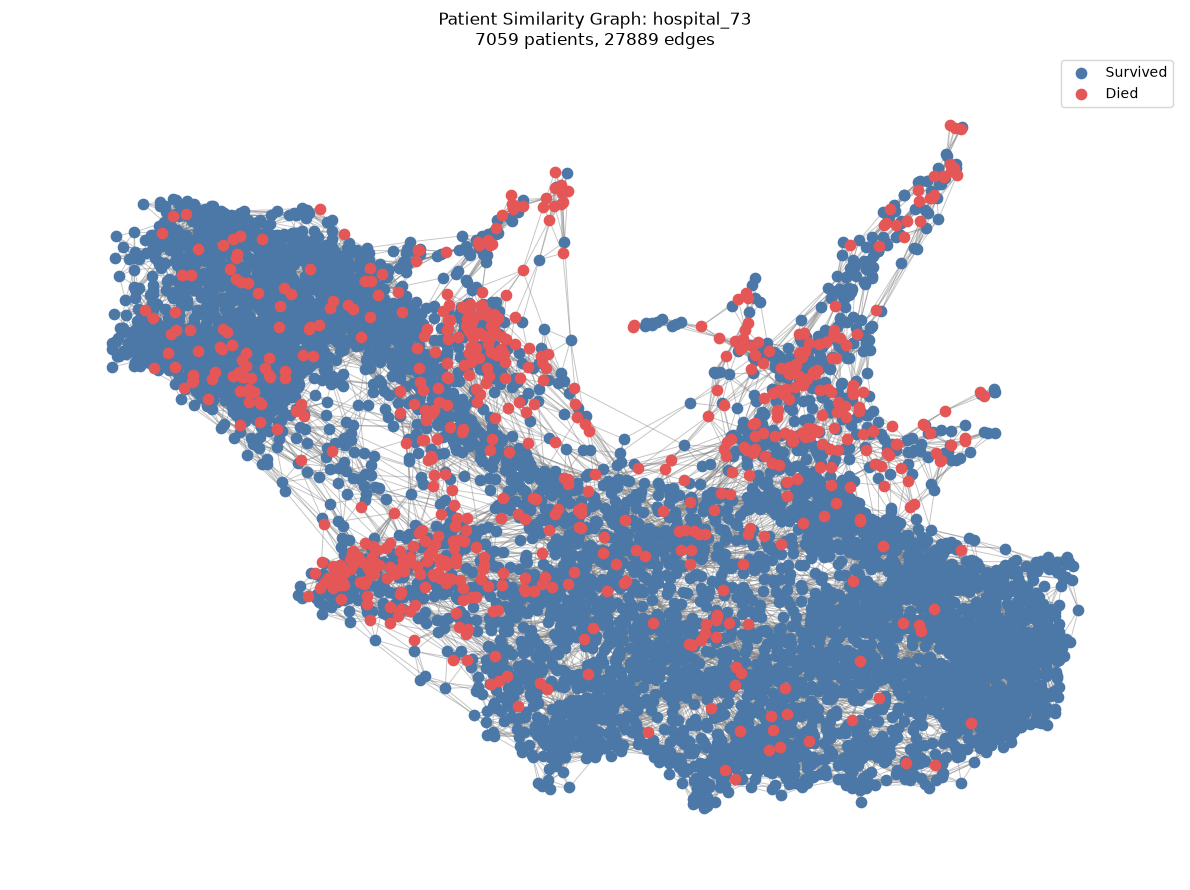

Hospital: hospital_73
Patients displayed: 7059
Edges displayed: 27889
Saved visualization: /Users/aryandwivedi/Desktop/Project Hail Minor/figures/graph_sample_train_concat.png


In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import load_npz
from matplotlib.lines import Line2D

_start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_start, *_start.parents] if (p / "checkpoints").exists() and (p / "processed").exists()), _start)
GRAPH_DIR = (
    PROJECT_ROOT
    / "checkpoints"
    / "fusion"
    / "patient_graphs_knn_concat"
)

# Load the training graph and its patient metadata.
A = load_npz(GRAPH_DIR / "adjacency_train.npz").tocsr()

with np.load(GRAPH_DIR / "nodes_train.npz") as data:
    patient_ids = data["patient_ids"]
    hospital_ids = data["hospital_ids"].astype(str)
    labels = data["labels"]

assert A.shape == (len(patient_ids), len(patient_ids))

# Choose a hospital with enough patients to display a useful graph.
rng = np.random.default_rng(39)
unique_hospitals, counts = np.unique(hospital_ids, return_counts=True)
candidates = unique_hospitals[counts >= 100]

if len(candidates):
    hospital = rng.choice(candidates)
else:
    hospital = unique_hospitals[np.argmax(counts)]

hospital_rows = np.flatnonzero(hospital_ids == hospital)
A_h = A[hospital_rows][:, hospital_rows].tocsr()
A_h.setdiag(0)
A_h.eliminate_zeros()

# Select a connected neighborhood with at most 120 patients.
MAX_NODES = 10000
seed = int(rng.integers(len(hospital_rows)))
selected = [seed]
seen = {seed}
queue = [seed]

while queue and len(selected) < MAX_NODES:
    node = queue.pop(0)
    neighbors = A_h.indices[
        A_h.indptr[node]:A_h.indptr[node + 1]
    ].copy()
    rng.shuffle(neighbors)

    for neighbor in neighbors:
        neighbor = int(neighbor)
        if neighbor not in seen:
            seen.add(neighbor)
            selected.append(neighbor)
            queue.append(neighbor)

            if len(selected) >= MAX_NODES:
                break

# Draw only edges between the selected patients.
A_local = A_h[selected][:, selected].tocoo()
G = nx.Graph()
G.add_nodes_from(range(len(selected)))
G.add_edges_from(
    (int(i), int(j))
    for i, j in zip(A_local.row, A_local.col)
    if i < j
)

global_rows = hospital_rows[np.asarray(selected)]
local_labels = labels[global_rows]

pos = nx.spring_layout(G, seed=42, k=0.7, iterations=50)

fig, ax = plt.subplots(figsize=(12, 9))

nx.draw_networkx_edges(
    G, pos, ax=ax, edge_color="gray",
    alpha=0.45, width=0.7
)

survivors = [
    i for i, label in enumerate(local_labels) if label == 0
]
deaths = [
    i for i, label in enumerate(local_labels) if label == 1
]

nx.draw_networkx_nodes(
    G, pos, nodelist=survivors,
    node_color="#4C78A8", node_size=55, ax=ax,
    label="Survived"
)
nx.draw_networkx_nodes(
    G, pos, nodelist=deaths,
    node_color="#E45756", node_size=55, ax=ax,
    label="Died"
)

ax.set_title(
    f"Patient Similarity Graph: {hospital}\n"
    f"{G.number_of_nodes()} patients, "
    f"{G.number_of_edges()} edges"
)
ax.legend()
ax.axis("off")
plt.tight_layout()

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
output_path = FIGURES_DIR / "graph_sample_train_concat.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Hospital:", hospital)
print("Patients displayed:", G.number_of_nodes())
print("Edges displayed:", G.number_of_edges())
print("Saved visualization:", output_path.resolve())
